# The Smoothing Trap: Can We Reconstruct the Sunspot Cycle Without a Model?

## Part I: Reconstructing the 11-Year Sunspot Cycle

In [7]:
import numpy as np
from matplotlib import pyplot as plt

### Step 1. Monthly mean sunspot numbers

The record `SN_m_tot_V2.0.txt` contains the monthly mean sunspot number from January 1749 to September 2026 (3333 months, without gaps). Column 1 is the year, column 2 is the month, and column 3 is the monthly mean sunspot number $R_i$. For plotting, the year and the month are combined into a decimal year $t_i = \text{year} + (\text{month} - 1)/12$.

In [8]:
# read data from the .txt file
sunspot_year, sunspot_month, sunspot = np.loadtxt("SN_m_tot_V2.0.txt", unpack=True)

# establish a decimal year time axis
sunspot_time = sunspot_year + (sunspot_month - 1) / 12

### Step 2. Classical 13-month running mean

The classical 13-month running mean estimates the sunspot number in month $i$ as a weighted average of the 13 neighbouring months:

$$
\bar{R}_i = \frac{1}{24} R_{i-6} + \frac{1}{12}\left(R_{i-5} + R_{i-4} + \dots + R_{i-1} + R_{i} + R_{i+1} + \dots + R_{i+5}\right) + \frac{1}{24} R_{i+6}
$$

The eleven inner months have the same weight $1/12$, and the two outer months have half of this weight, so that the weights sum to one. The weights are fixed in advance and do not depend on the data.

For the first and the last six months of the record the full window is not available, so the smoothed value is the mean of the measurements that fall inside the window.

In [9]:
# apply a 13-month running mean 
def smooth_by_running_mean(data, time):
    n = len(time)
    running_mean_13 = data.copy()

    for i in range(0, 6):
        running_mean_13[i] = np.mean(data[0 : i + 7])

    for i in range(6, n - 6):
        mean = (data[i-6] + data[i+6]) / 24

        for j in range(i-5, i+6):
            mean += data[j] / 12

        running_mean_13[i] = mean

    for i in range(n - 6, n):
        running_mean_13[i] = np.mean(data[i - 6 : n])

    return running_mean_13

sunspot_number_running_mean_smoothing = smooth_by_running_mean(sunspot, sunspot_time)

### Step 3. 13-month optimal running mean

The 13-month optimal running mean follows the method presented on page 31 of the lecture *Process reconstruction free from any constraints and assumptions*, with the prescribed smoothing coefficient $\beta = 0.01$.

**Optimal approximation as a weighted sum of measurements.** Inside a 13-month window centred at month $i$, the optimal approximation $\hat{X}$ is a weighted sum of the measurements $Z$:

$$
\hat{X} = \beta A^{-1} Z
$$

Written for all 13 months of the window, this is

$$
\hat{X} =
\begin{pmatrix} x_{i-6} \\ x_{i-5} \\ \vdots \\ x_i \\ \vdots \\ x_{i+5} \\ x_{i+6} \end{pmatrix}
= \beta
\begin{pmatrix}
c_{1,1} & c_{1,2} & \cdots & c_{1,7} & \cdots & c_{1,12} & c_{1,13} \\
c_{2,1} & c_{2,2} & \cdots & c_{2,7} & \cdots & c_{2,12} & c_{2,13} \\
\vdots & \vdots & & \vdots & & \vdots & \vdots \\
c_{7,1} & c_{7,2} & \cdots & c_{7,7} & \cdots & c_{7,12} & c_{7,13} \\
\vdots & \vdots & & \vdots & & \vdots & \vdots \\
c_{12,1} & c_{12,2} & \cdots & c_{12,7} & \cdots & c_{12,12} & c_{12,13} \\
c_{13,1} & c_{13,2} & \cdots & c_{13,7} & \cdots & c_{13,12} & c_{13,13}
\end{pmatrix}
\begin{pmatrix} z_{i-6} \\ z_{i-5} \\ \vdots \\ z_i \\ \vdots \\ z_{i+5} \\ z_{i+6} \end{pmatrix}
$$

where $A$ is a $13 \times 13$ five-diagonal banded matrix and $c_{jk}$ are the elements of $A^{-1}$.

**Estimate at the central month.** Only the estimate at the central month $x_i$ is kept, so only the 7th row of $A^{-1}$ is needed:

$$
x_i = \beta\, C(\beta)\, Z, \qquad C(\beta) = \left(c_{7,1}, c_{7,2}, \dots, c_{7,7}, \dots, c_{7,12}, c_{7,13}\right)
$$

The vector $\beta\, C(\beta)$ contains the 13 weights of the optimal running mean. They are computed once and then applied to every 13-month window along the record, in the same way as the weights of the classical running mean. For the first and the last six months the smoothed value is the mean of the available measurements, as in Step 2.

**Which measurements matter most?** In the classical running mean all inner months have the same weight. In the optimal running mean the weights depend on $\beta$, so the contribution of each month is determined by the method itself. The weights are shown in the bar chart below the code.

**Where the matrix $A$ comes from.** The optimal approximation is a compromise between two requirements: the estimate should be close to the measurements, and it should be smooth. This is expressed by the criterion

$$
J = \sum_{k} (z_k - x_k)^2 + \frac{1}{\beta} \sum_{k} (x_{k+1} - 2x_k + x_{k-1})^2 \rightarrow \min
$$

The first term is the deviation from the measurements and the second term is the variability (sum of squared second differences), so a small $\beta$ gives a strong penalty for variability and a smoother estimate. With the $11 \times 13$ matrix of second differences $D$, whose rows are $(\dots, 1, -2, 1, \dots)$, the criterion becomes $J = (Z - X)^T (Z - X) + \frac{1}{\beta} (DX)^T (DX)$. Setting its derivative with respect to $X$ to zero gives

$$
(D^T D + \beta I)\, X = \beta Z
\quad \Rightarrow \quad
\hat{X} = \beta A^{-1} Z, \qquad A = D^T D + \beta I,
$$

$$
A =
\begin{pmatrix}
1+\beta & -2 & 1 & & & & \\
-2 & 5+\beta & -4 & 1 & & & \\
1 & -4 & 6+\beta & -4 & 1 & & \\
& \ddots & \ddots & \ddots & \ddots & \ddots & \\
& & 1 & -4 & 6+\beta & -4 & 1 \\
& & & 1 & -4 & 5+\beta & -2 \\
& & & & 1 & -2 & 1+\beta
\end{pmatrix}
$$

which is the five-diagonal banded matrix from the lecture. Since the second differences of a constant signal are zero, $A \mathbf{1} = \beta \mathbf{1}$, so the weights $\beta\, C(\beta)$ sum to one and the method does not shift the level of the signal.

Weights of the 13-month optimal running mean, β = 0.01:
[0.0228 0.0442 0.0653 0.0855 0.1035 0.1171 0.1231 0.1171 0.1035 0.0855
 0.0653 0.0442 0.0228]
Sum of the weights: 1.0000


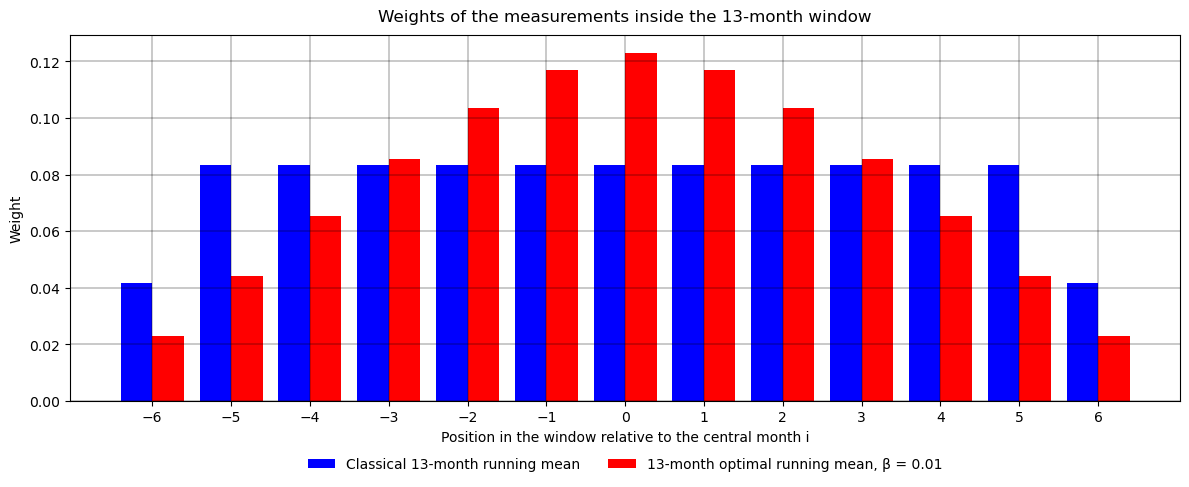

In [16]:
# develop the 13-month optimal running mean for the sunspot record
BETA = 0.01
WINDOW_SIZE = 13

# the optimal approximation inside the 13-month window: X = beta * A^-1 * Z
# A = D^T D + beta * I, where D is the matrix of second differences,
def get_optimal_weights(beta, window_size):
    D = np.zeros((window_size - 2, window_size))
    for k in range(window_size - 2):
        D[k, k : k + 3] = [1, -2, 1]

    A = D.T @ D + beta * np.eye(window_size)

    # weights of the measurements for the central point x_i
    return beta * np.linalg.inv(A)[window_size // 2]

optimal_weights = get_optimal_weights(BETA, WINDOW_SIZE)
print(f"Weights of the 13-month optimal running mean, β = {BETA}:\n{np.round(optimal_weights, 4)}")
print(f"Sum of the weights: {np.sum(optimal_weights):.4f}")

# compare the weights of the classical and the optimal running means
classical_weights = np.array([1/24] + [1/12] * 11 + [1/24])
window_positions = np.arange(-6, 7)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(window_positions - 0.2, classical_weights, width=0.4, color="blue", label="Classical 13-month running mean")
ax.bar(window_positions + 0.2, optimal_weights, width=0.4, color="red", label=f"13-month optimal running mean, β = {BETA}")
ax.set_title("Weights of the measurements inside the 13-month window", pad=10)
ax.set_xlabel("Position in the window relative to the central month i")
ax.set_ylabel("Weight")
ax.set_xticks(window_positions)
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()

In [17]:
# apply the 13-month optimal running mean
def smooth_by_optimal_running_mean(data, time):
    n = len(time)
    optimal_running_mean_13 = data.copy()

    for i in range(0, 6):
        optimal_running_mean_13[i] = np.mean(data[0 : i + 7])

    for i in range(6, n - 6):
        optimal_running_mean_13[i] = np.sum(optimal_weights * data[i - 6 : i + 7])

    for i in range(n - 6, n):
        optimal_running_mean_13[i] = np.mean(data[i - 6 : n])

    return optimal_running_mean_13

sunspot_number_optimal_running_mean = smooth_by_optimal_running_mean(sunspot, sunspot_time)

## Part II: When Smoothing Changes the Story

### Step 4. Comparison of the reconstructed solar cycle

The original monthly sunspot numbers, the classical 13-month running mean and the 13-month optimal running mean are plotted on the same graph for the whole record. The second graph zooms in on cycles 24 and 25 (from 2008), where the individual peaks and troughs of the monthly data and of both smoothed curves can be compared in detail.

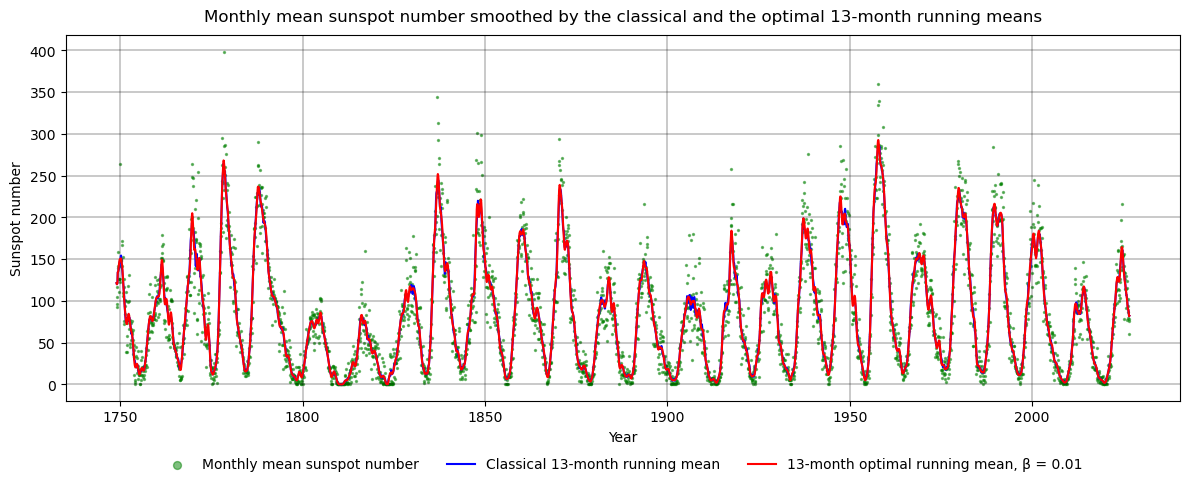

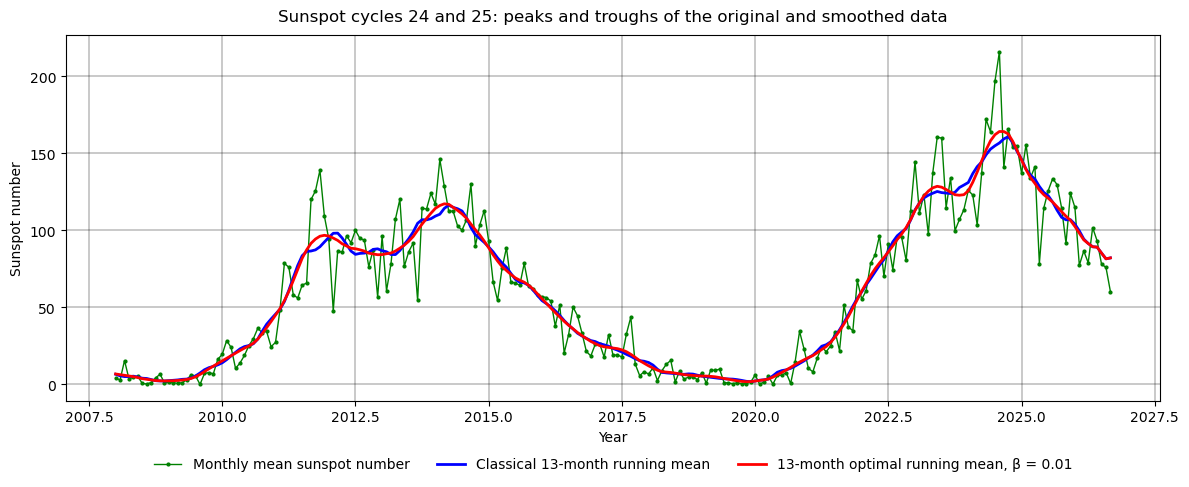

In [19]:
# plot the original monthly sunspot numbers, the classical and the optimal 13-month running means
fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(sunspot_time, sunspot, s=2, color="green", alpha=0.5, label="Monthly mean sunspot number")
ax.plot(sunspot_time, sunspot_number_running_mean_smoothing, linewidth=1.5, color="blue", label="Classical 13-month running mean")
ax.plot(sunspot_time, sunspot_number_optimal_running_mean, linewidth=1.5, color="red", label=f"13-month optimal running mean, β = {BETA}")
ax.set_title("Monthly mean sunspot number smoothed by the classical and the optimal 13-month running means", pad=10)
ax.set_xlabel("Year")
ax.set_ylabel("Sunspot number")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=False, markerscale=4, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()

# zoom in on the last two cycles to compare peaks and troughs in detail
zoom_mask = sunspot_time >= 2008

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(sunspot_time[zoom_mask], sunspot[zoom_mask], linewidth=1, color="green", marker="o", markersize=2, label="Monthly mean sunspot number")
ax.plot(sunspot_time[zoom_mask], sunspot_number_running_mean_smoothing[zoom_mask], linewidth=2, color="blue", label="Classical 13-month running mean")
ax.plot(sunspot_time[zoom_mask], sunspot_number_optimal_running_mean[zoom_mask], linewidth=2, color="red", label=f"13-month optimal running mean, β = {BETA}")
ax.set_title("Sunspot cycles 24 and 25: peaks and troughs of the original and smoothed data", pad=10)
ax.set_xlabel("Year")
ax.set_ylabel("Sunspot number")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()

#### Investigation: does the optimal running mean produce inverse oscillations?

A running mean with fixed weights $w_k$ is a linear filter, so its effect on an oscillation depends only on the period of this oscillation. To see this effect directly, each method is applied to a pure sine wave $s_i = \sin(2\pi i / P)$ with period $P$, and the result $\hat{s}_i$ is compared with the original wave through the gain

$$
G(P) = \frac{\sum_i \hat{s}_i\, s_i}{\sum_i s_i^2}
$$

- $G \approx 1$: the oscillation is kept;
- $G = 0$: the oscillation is erased;
- $G < 0$: the oscillation is **inverted** — its maxima become minima and vice versa.

The first and the last 24 months are excluded from the sums, because the edges of the record are treated differently. Periods from 2 to 60 months are examined.

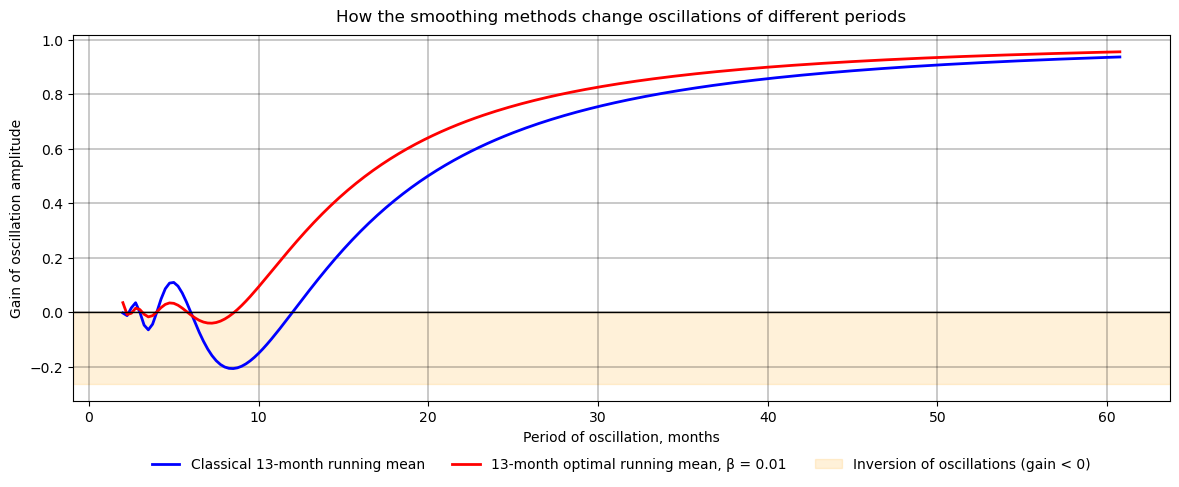

In [12]:
# check which oscillations each method inverts:
# smooth a pure sine wave with a given period and compare the result with the original wave
# gain = 1 - the oscillation is kept, gain = 0 - it is erased, gain < 0 - maxima turn into minima (inversion)
def get_oscillation_gain(smoothing_function, period_months):
    steps = np.arange(sunspot.size)
    wave = np.sin(2 * np.pi * steps / period_months)
    smoothed_wave = smoothing_function(wave, steps)

    # the first and last months are skipped, because the edges are treated differently
    inner = slice(24, -24)
    return np.sum(smoothed_wave[inner] * wave[inner]) / np.sum(wave[inner]**2)

periods_months = np.arange(2, 61, 0.25)
classical_gain = np.array([get_oscillation_gain(smooth_by_running_mean, period) for period in periods_months])
optimal_gain = np.array([get_oscillation_gain(smooth_by_optimal_running_mean, period) for period in periods_months])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(periods_months, classical_gain, linewidth=2, color="blue", label="Classical 13-month running mean")
ax.plot(periods_months, optimal_gain, linewidth=2, color="red", label=f"13-month optimal running mean, β = {BETA}")
ax.axhline(0, color="black", linewidth=1)
ax.axhspan(ax.get_ylim()[0], 0, color="orange", alpha=0.15, label="Inversion of oscillations (gain < 0)")
ax.set_title("How the smoothing methods change oscillations of different periods", pad=10)
ax.set_xlabel("Period of oscillation, months")
ax.set_ylabel("Gain of oscillation amplitude")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()

### Step 5. Deviation and variability indicators

The two methods are compared with the indicators discussed in the lecture. The deviation indicator shows how closely the smoothed curve $\hat{R}_i$ follows the measurements $R_i$, and the variability indicator shows how smooth the curve is:

$$
I_d = \sum_{i=1}^{N} \left(R_i - \hat{R}_i\right)^2, \qquad
I_v = \sum_{i=1}^{N-2} \left(\hat{R}_{i+2} - 2\hat{R}_{i+1} + \hat{R}_i\right)^2
$$

The two indicators pull in opposite directions: a smoother curve usually deviates more from the measurements. A method is preferable if it keeps both indicators small.

In [13]:
# find the indicatiors of smoothing performance (from assignment 3)
def find_smoothing_indicators(measured, estimated):
    deviation = np.sum((measured - estimated)**2)
    variability = np.sum((estimated[2:] - 2*estimated[1:-1] + estimated[:-2])**2)

    return deviation, variability

running_mean_dev, running_mean_var = find_smoothing_indicators(sunspot, sunspot_number_running_mean_smoothing)
print(f"Classical 13-month running mean: deviation indicator = {running_mean_dev:.1f}, variability indicator = {running_mean_var:.1f}")

optimal_running_mean_dev, optimal_running_mean_var = find_smoothing_indicators(sunspot, sunspot_number_optimal_running_mean)
print(f"13-month optimal running mean, β = {BETA}: deviation indicator = {optimal_running_mean_dev:.1f}, variability indicator = {optimal_running_mean_var:.1f}")

Classical 13-month running mean: deviation indicator = 1560752.5, variability indicator = 12194.9
13-month optimal running mean, β = 0.01: deviation indicator = 1340010.2, variability indicator = 3738.6
